# RMS Titanic: Exploratory Data Analysis & Feature Dynamics
**File:** `01_titanic_exploratory_data_analysis.ipynb`

### Scope & Objectives
This notebook carries out in-depth Exploratory Data Analysis (EDA) on the pre-cleaned dataset (`titanic_cleaned.csv`). 

The analytical focus includes:
1. Target distribution and base survival rates.
2. Demographic interactions (Sex, Age profiles) with survival.
3. Socio-economic gradients (Passenger Class, Fare distributions).
4. Family unit structures (`sibsp`, `parch`, and potential combinations).
5. Port of embarkation dynamics.
6. Initial collinearity assessments among continuous features to inform modeling.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

# Locate processed data
data_path = Path.cwd().parent / "Data" / "Processed" / "titanic_cleaned.csv"
if not data_path.exists():
    data_path = Path.cwd() / "Data" / "Processed" / "titanic_cleaned.csv"

df = pd.read_csv(data_path)
print(f"Loaded {df.shape[0]} records across {df.shape[1]} features.")
df.info()

Loaded 891 records across 8 features.
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    str    
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 55.8 KB


## 1. Target Class Distribution (`survived`)
We first inspect the class balance of our target outcome. 
- `0`: Did not survive
- `1`: Survived

,Count,Percentage (%)
Outcome,,
0,549,61.62
1,342,38.38


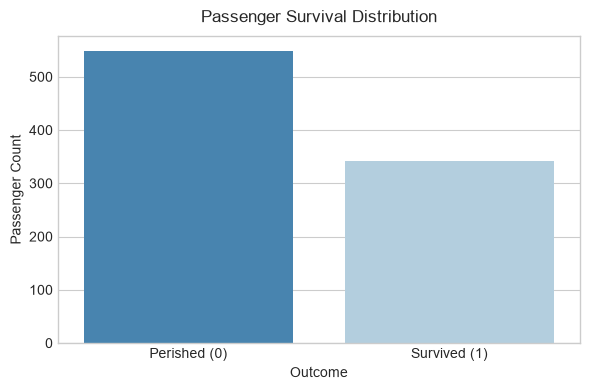

In [3]:
# Calculate survival counts and percentages
target_counts = df['survived'].value_counts()
target_props = df['survived'].value_counts(normalize=True) * 100

# Create a summary table
summary_target = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_props
}, index=[0, 1])

summary_target.index.name = 'Outcome'
display(summary_target.round(2))

# Visualise passenger survival distribution
fig, ax = plt.subplots(figsize=(6, 4))

sns.countplot(
    data=df,
    x='survived',
    hue='survived',
    palette='Blues_r',
    legend=False,
    ax=ax
)

ax.set_title('Passenger Survival Distribution', fontsize=12, pad=10)
ax.set_xlabel('Outcome')
ax.set_ylabel('Passenger Count')

# Set tick positions and labels explicitly
ax.set_xticks([0, 1])
ax.set_xticklabels(['Perished (0)', 'Survived (1)'])

plt.tight_layout()
plt.show()

> ### Analytical Takeaway: Class Balance & Baseline Benchmark
> - **Inherent Imbalance:** The target outcome is moderately imbalanced, with **61.6%** (549 passengers) perishing and **38.4%** (342 passengers) surviving.
> - **Evaluation Metric Impact:** A naive majority-class rule (predicting everyone died) establishes a baseline accuracy of ~61.6%. Accuracy alone will therefore be misleading; our logistic regression workflow will need to track precision, recall, and ROC-AUC to reliably evaluate minority-class identification.

## 2. Demographic Analysis: Sex & Age
Historical records highlight the maritime protocol of prioritising women and children. Here we evaluate whether this pattern manifests distinctly in the survival rates.

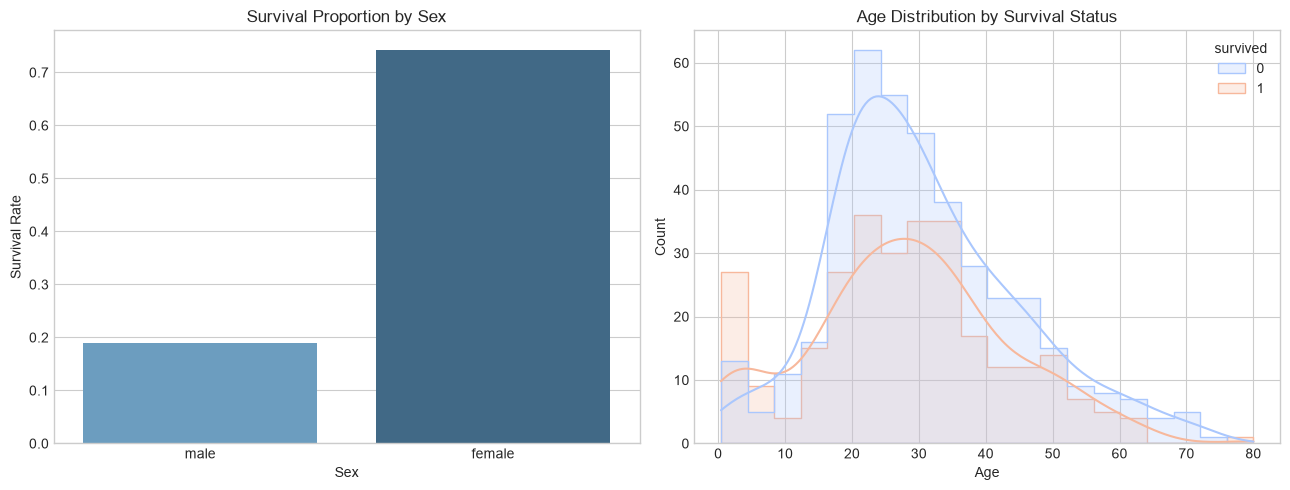

,total,survivors,survival_rate
sex,,,
female,314,233,74.20
male,577,109,18.89


In [5]:
#%%
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Survival rate by Sex
sns.barplot(
    data=df,
    x='sex',
    y='survived',
    hue='sex',
    palette='Blues_d',
    legend=False,
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Survival Proportion by Sex')
axes[0].set_ylabel('Survival Rate')
axes[0].set_xlabel('Sex')

# Age distribution segmented by survival status
sns.histplot(
    data=df,
    x='age',
    hue='survived',
    kde=True,
    element='step',
    palette='coolwarm',
    ax=axes[1]
)

axes[1].set_title('Age Distribution by Survival Status')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Granular survival rates by sex
sex_summary = df.groupby('sex')['survived'].agg(
    total='count',
    survivors='sum',
    survival_rate=lambda x: x.mean() * 100
).round(2)

display(sex_summary)

> ### Analytical Takeaway: Demographic Disparities
> - **Severe Gender Divergence:** Female passengers achieved a survival rate of **74.2%**, whereas male passengers recorded only **18.9%**. This empirical gap directly mirrors the historical enforcement of the *"women and children first"* protocol.
> - **Age Profile Dynamics:** While the core mortality peak lies heavily across young working-age adults (approx. 18–35 years, predominantly male crew and steerage), infants and young children under age 5 show an elevated survival proportion.
> - **Modelling Consideration:** The binary indicator `sex` will likely emerge as the single most influential negative coefficient for male records in the regression log-odds.

## 3. Socio-Economic Stratification: Passenger Class & Fare
We assess whether higher ticketing tiers and greater fares yielded better survival probability due to deck accessibility and emergency placement.

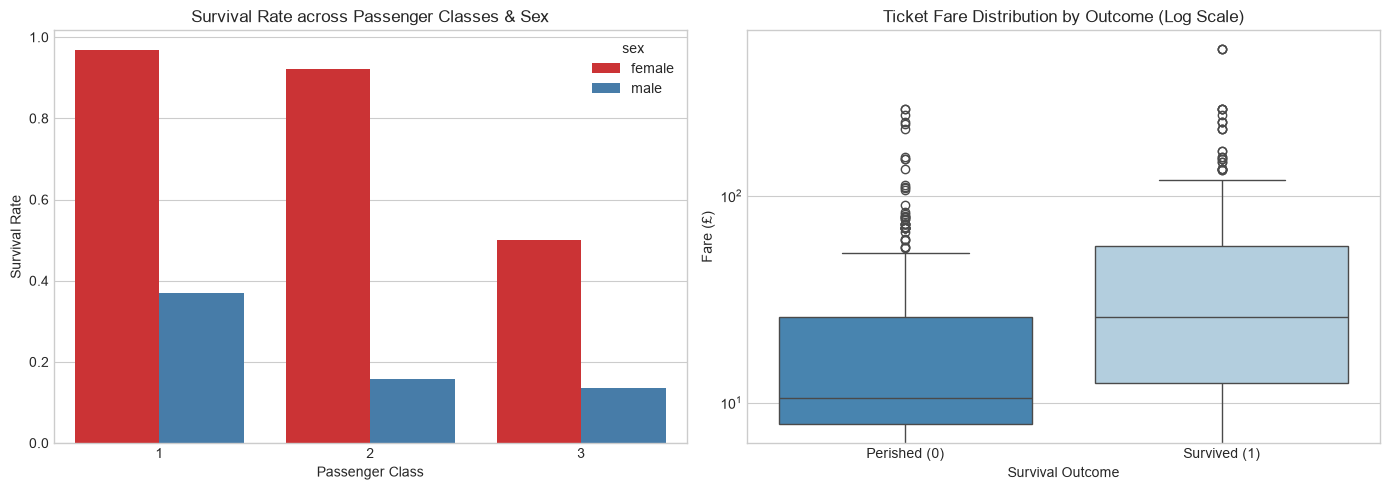

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Survival rate by Passenger Class and Sex
sns.barplot(
    data=df,
    x='pclass',
    y='survived',
    hue='sex',
    palette='Set1',
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Survival Rate across Passenger Classes & Sex')
axes[0].set_xlabel('Passenger Class')
axes[0].set_ylabel('Survival Rate')

# Log-scaled Fare comparison
sns.boxplot(
    data=df,
    x='survived',
    y='fare',
    hue='survived',
    palette='Blues_r',
    legend=False,
    ax=axes[1]
)

axes[1].set_yscale('log')
axes[1].set_title('Ticket Fare Distribution by Outcome (Log Scale)')
axes[1].set_xlabel('Survival Outcome')
axes[1].set_ylabel('Fare (£)')

axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Perished (0)', 'Survived (1)'])

plt.tight_layout()
plt.show()

> ### Analytical Takeaway: Socio-Economic Gradients
> - **Class Privilege Gradient:** Survival odds deteriorate sharply moving down passenger tiers. 1st Class passengers experienced the highest survival rates, whereas 3rd Class passengers suffered the greatest loss of life across both genders.
> - **Financial Indicators:** The median ticket fare among survivors is noticeably higher than among those who died, as reflected in the log-scale boxplot. 
> - **Structural Mechanisms:** Cabin locations on upper decks granted 1st and 2nd Class travellers immediate physical proximity to lifeboats and earlier emergency notification compared to steerage quarters below deck.

## 4. Family Dynamics (`sibsp` & `parch`)
We inspect whether traveling with relatives influenced survival chances, testing both raw counts and an engineered aggregate (`family_size`).

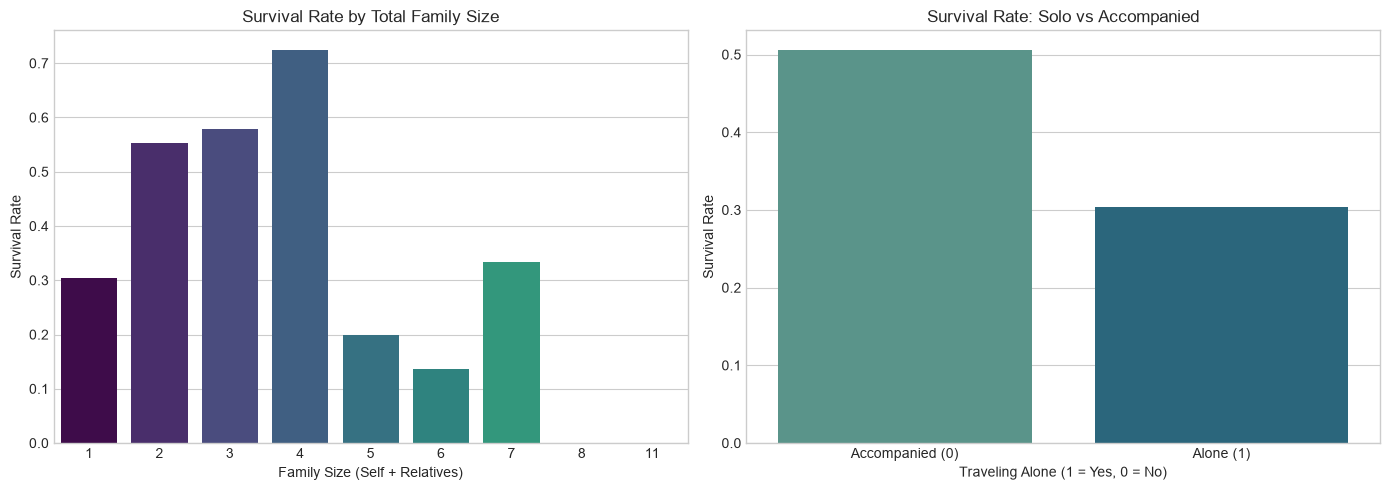

In [12]:
# Compute composite family metric
df_family = df.copy()
df_family['family_size'] = df_family['sibsp'] + df_family['parch'] + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Survival rate by family size
sns.barplot(
    data=df_family,
    x='family_size',
    y='survived',
    hue='family_size',
    palette='viridis',
    legend=False,
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Survival Rate by Total Family Size')
axes[0].set_xlabel('Family Size (Self + Relatives)')
axes[0].set_ylabel('Survival Rate')

# Lone travelers vs accompanied travelers
df_family['is_alone'] = (df_family['family_size'] == 1).astype(int)

sns.barplot(
    data=df_family,
    x='is_alone',
    y='survived',
    hue='is_alone',
    palette='crest',
    legend=False,
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title('Survival Rate: Solo vs Accompanied')
axes[1].set_xlabel('Traveling Alone (1 = Yes, 0 = No)')
axes[1].set_ylabel('Survival Rate')

axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Accompanied (0)', 'Alone (1)'])

plt.tight_layout()
plt.show()

> ### Analytical Takeaway: Family Unit Dynamics
> - **Non-Linear Group Effect:** Survival follows an inverted U-shaped pattern. Solo travellers (`family_size = 1`) experienced a low survival rate (~30%). Moderate family units of 2 to 4 individuals experienced peak survival rates (over 50%).
> - **Large Family Penalty:** For extended families of 5 or more, survival drops abruptly. Navigating evacuation decks, gathering dependants, and locating sufficient lifeboat spaces together proved detrimental during the crisis.
> - **Feature Engineering Opportunity:** Creating a consolidated `family_size` or an `is_alone` flag provides a cleaner, more interpretable signal than treating `sibsp` and `parch` as purely independent linear factors.

## 5. Port of Embarkation (`embarked`)
We examine whether embarkation location (`C = Cherbourg`, `Q = Queenstown`, `S = Southampton`) exhibits distinct survival discrepancies, likely mediated by passenger class differences.

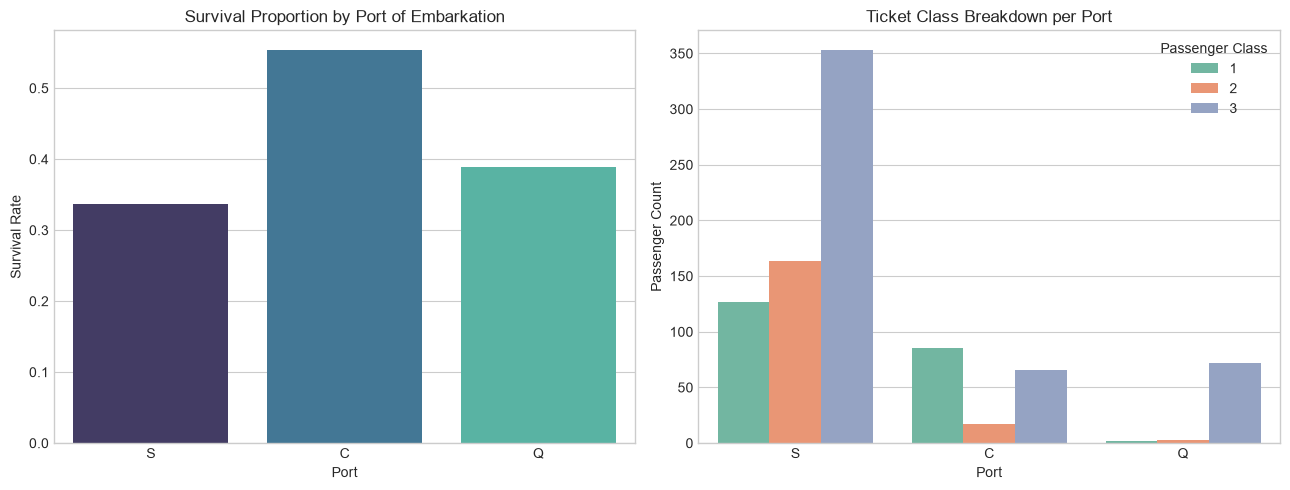

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Survival rate by port of embarkation
sns.barplot(
    data=df,
    x='embarked',
    y='survived',
    hue='embarked',
    palette='mako',
    legend=False,
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Survival Proportion by Port of Embarkation')
axes[0].set_xlabel('Port')
axes[0].set_ylabel('Survival Rate')

# Class distribution across ports
sns.countplot(
    data=df,
    x='embarked',
    hue='pclass',
    palette='Set2',
    ax=axes[1]
)

axes[1].set_title('Ticket Class Breakdown per Port')
axes[1].set_xlabel('Port')
axes[1].set_ylabel('Passenger Count')
axes[1].legend(title='Passenger Class')

plt.tight_layout()
plt.show()

> ### Analytical Takeaway: Embarkation Dynamics & Confounding
> - **Port Divergence:** Passengers embarking at **Cherbourg (C)** exhibited the highest survival proportion (~55%), whereas **Southampton (S)** and **Queenstown (Q)** had lower survival rates (~34–39%).
> - **Confounding with Socio-Economic Status:** This discrepancy is largely confounded by passenger class: Cherbourg had a much higher proportion of 1st Class bookings, whereas Queenstown passengers were almost entirely 3rd Class steerage.
> - **Modelling Consideration:** One-hot encoding `embarked` will allow the regression model to control for port effects alongside `pclass` and `fare` simultaneously.

## 6. Correlation Analysis & Feature Interactions
Before fitting a logistic regression model, we inspect bivariate correlations among all numerical metrics to identify potential collinearity risks.

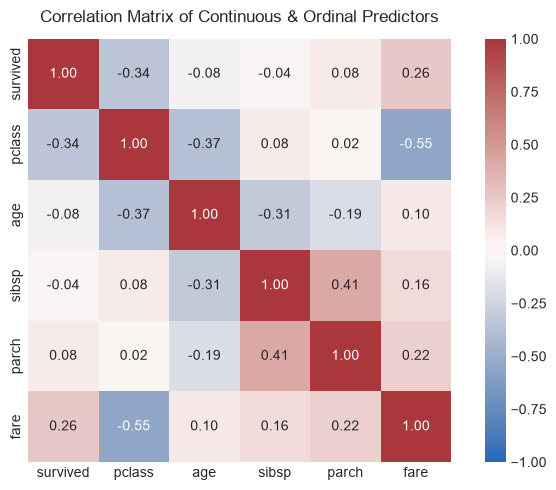

In [9]:
numeric_cols = ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='vlag', vmin=-1, vmax=1, square=True)
plt.title('Correlation Matrix of Continuous & Ordinal Predictors', pad=12)
plt.tight_layout()
plt.show()

> ### Analytical Takeaway: Collinearity Diagnostics
> - **Primary Associations with Target:** `pclass` exhibits a moderate negative correlation with `survived` (higher numerical class = lower tier = lower survival), while `fare` shows a positive correlation.
> - **Inter-Feature Correlation:** A notable negative correlation exists between `pclass` and `fare` (-0.55), as expected. `sibsp` and `parch` correlate moderately (+0.41), reflecting shared family units.
> - **Multicollinearity Verdict:** None of the pairwise linear correlations between continuous/ordinal features exceed |0.60|, suggesting that multicollinearity will remain well within manageable bounds for logistic regression estimation (to be formally verified via VIF in Notebook 2).

## 7. Synthesis & Strategic Handover to Modelling

### Executive Summary of Exploratory Insights
Across 891 passenger records, survival was governed predominantly by structural protocols and physical accommodation location rather than random chance:

1. **The Demographic Hierarchy:**
   - **Sex:** The strongest bivariate predictor. Female passengers experienced a **74.2%** survival rate versus **18.9%** for males, confirming the strict enforcement of the *"women and children first"* maritime convention.
   - **Age:** Early childhood (under 5 years) afforded protective benefits, while working-age males suffered disproportionately high mortality.

2. **Socio-Economic & Physical Privilege:**
   - **Ticket Class (`pclass`):** A pronounced survival gradient exists from 1st Class down to 3rd Class across all cohorts.
   - **Ticket Fare:** Corroborates class tier findings; passengers paying higher fares held accommodation closer to boat decks and received earlier muster warnings.
   - **Embarkation (`embarked`):** The apparent advantage of Cherbourg passengers (~55% survival) is heavily confounded by the disproportionate concentration of wealthy 1st Class tickets originating from that port.

3. **Family Structures & Evacuation Mechanics:**
   - Family size exhibits a distinct non-linear dynamic. Travelling alone carried high mortality (~30% survival), whilst small families (2–4 members) saw survival rates exceed 50%.
   - Larger family units (5+ members) suffered an abrupt drop in survival, reflecting the logistical friction of coordinating dependants during an emergency muster.

---

### Architectural Decisions for Notebook 2 (`02_titanic_logistic_regression.ipynb`)

| Area | EDA Observation | Action in Logistic Regression Pipeline |
| :--- | :--- | :--- |
| **Leakage Control** | Missing values exist in `age` (~19.9%) and `embarked` (2 records). | All imputation (`SimpleImputer`) must be encapsulated strictly within a `scikit-learn Pipeline` fitted solely on training splits. |
| **Feature Scaling** | `age` and `fare` operate on divergent continuous scales; `fare` displays positive skewness. | Apply `StandardScaler` to continuous predictors to guarantee smooth gradient convergence and unskew coefficient penalties. |
| **Categorical Encoding** | `sex`, `embarked`, and `pclass` represent discrete groupings. | Apply `OneHotEncoder(drop='first')` to prevent dummy variable traps while maintaining interpretable reference baselines. |
| **Multicollinearity** | `pclass` and `fare` correlate moderately (-0.55), as do `sibsp` and `parch` (+0.41). | Verified that pairwise linear correlation does not exceed severe thresholds; formal VIF diagnostics will be calculated prior to training. |
| **Baseline Benchmark** | Majority class ("Perished") accounts for 61.6% of historical outcomes. | Benchmark models against a naive `DummyClassifier`, relying on **ROC-AUC**, **Precision**, **Recall**, and **F1-Score** rather than raw accuracy. |
| **Feature Engineering** | Inverted U-shape behaviour between family count and survival. | Benchmark raw `sibsp`/`parch` predictors against a unified `family_size` feature to assess model performance gains. |